# 01 — Exploratory Data Analysis

**Mục tiêu:** mô tả phân bố bệnh, đặc điểm triệu chứng, mức dư thừa và khả năng phân biệt trên dữ liệu quan sát.
**Câu hỏi nghiên cứu:** bao nhiêu lớp đủ support độc lập? Triệu chứng nào phổ biến/hiếm/hằng? Có dấu hiệu shortcut, profile tương tự và vector xung đột không? Điều đó ảnh hưởng thiết kế thí nghiệm thế nào?

Đọc toàn bộ CSV. Đây là EDA mô tả; không fit phép biến đổi, không chọn tập đặc trưng để huấn luyện, không thử mô hình. Hình chỉ hiện các tập con có tiêu chí chọn rõ; bảng CSV lưu đầy đủ.

Runtime chung Colab/Drive: [hướng dẫn duy nhất](../docs/phase3_colab.md). Cấu hình ở `configs/runtime.json`; source từ Drive, thực thi trong `/content`. Outputs đã lưu là lịch sử, không phải bằng chứng đã chạy trên Colab.

In [1]:
import runpy, platform
from pathlib import Path
if platform.system() != 'Linux' or not Path('/content').is_dir():
    raise RuntimeError('Chọn Google Colab kernel; /content phải là ổ tạm của runtime.')
DRIVE_ROOT = Path('/content/drive/MyDrive/ML_Projects/disease-prediction-ml')  # Locator sinh từ configs/runtime.json
entry = DRIVE_ROOT / 'src/data/colab_runtime.py'
if not entry.is_file():
    raise FileNotFoundError(f'Không thấy {entry}. Mount Drive và Publish source bằng prepare_colab_source.ps1; không upload script riêng.')
EXPECTED_RUNTIME_PAYLOAD = globals().get('EXPECTED_RUNTIME_PAYLOAD') or input('Paste RUNTIME_PAYLOAD_SHA256 from local Publish: ').strip()
RUNTIME = runpy.run_path(str(entry))['bootstrap_runtime'](DRIVE_ROOT, phase=1, expected_payload_sha256=EXPECTED_RUNTIME_PAYLOAD)
ROOT, runtime_paths = RUNTIME.paths.project_root, RUNTIME.paths

Stage A PASS | Colab Python 3.13.16 | Drive=/content/drive/MyDrive/ML_Projects/disease-prediction-ml | runtime/Drive read-write OK
Stage B PASS | imports=/content/disease-prediction-ml-runtime | source fingerprint=95b01d6ea67d68f9bbc48b647ca15b3c38219baac15639ae78637f184806bd61


In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from src.data.io import read_config, save_json
from src.data.loader import dataset_path, load_dataset, prepare_dataset, sha256_file
from src.data.audit import audit_dataset
config = read_config(ROOT)
np.random.seed(config["seed"])
source_path = dataset_path(runtime_paths, config)
path = prepare_dataset(runtime_paths, source_path)
df = load_dataset(path, config["target"])
OUTPUT = runtime_paths.new_run()
save_json(OUTPUT.metadata_dir / "runtime.json", {
    **runtime_paths.as_dict(), "source_csv": str(source_path), "read_csv": str(path),
    "source_sha256": sha256_file(source_path), "run_id": OUTPUT.run_id,
})
print(f"Runtime: {runtime_paths.runtime}; CSV nguồn: {source_path}")
print(f"Run ID: {OUTPUT.run_id}")
print(f"Báo cáo mới: {OUTPUT.reports_dir}; metadata: {OUTPUT.metadata_dir}")
print(f"Đọc toàn bộ {len(df):,} dòng, {df.shape[1]} cột từ {path.name}. Raw chỉ được đọc.")

Runtime: colab; CSV nguồn: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/data/raw/Disease and symptoms dataset.csv
Run ID: phase1-20261027T135804596614Z-65ea3750
Báo cáo mới: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/reports/runs/phase1-20261027T135804596614Z-65ea3750; metadata: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/artifacts/metadata/runs/phase1-20261027T135804596614Z-65ea3750
Đọc toàn bộ 246,945 dòng, 378 cột từ Disease and symptoms dataset.csv. Raw chỉ được đọc.


In [3]:
import matplotlib.pyplot as plt
from src.data.eda import analyze_eda, export_eda
from src.evaluation import plots
from src.evaluation.report import write_eda_report
from src.data.io import sha256_file
before = sha256_file(path)
audit = audit_dataset(df, config)
eda = analyze_eda(df, audit, config)
s, e = audit["summary"], eda["summary"]
plots.configure_plots()
def show(fig):
    display(fig)
    plt.close(fig)

## A. Phân bố nhãn
Histogram và đường hạng mô tả toàn bộ lớp mà không gắn hàng trăm nhãn. Hai biểu đồ ngang hiển thị 15 lớp ở mỗi đầu; những lớp bằng tần suất được xếp theo tên.

,quantile,samples
0,0.00,1.0
1,0.01,1.0
2,0.05,3.0
3,0.25,30.0
4,0.50,168.0
5,0.75,505.0
6,0.95,913.0
7,0.99,1215.0
8,1.00,1219.0


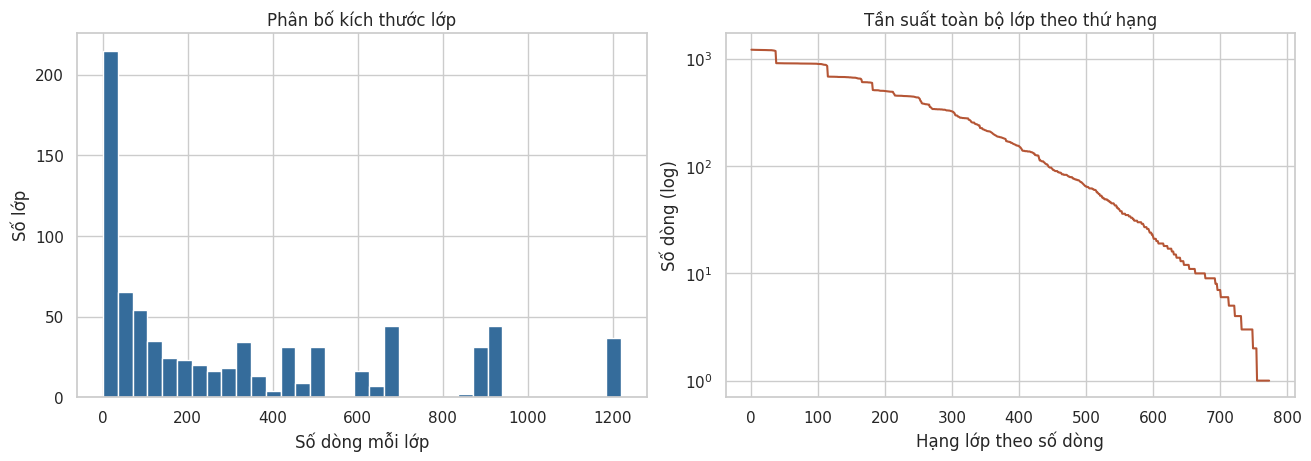

Mỗi lớp có 1–1,219 dòng, trung vị 168; tỷ lệ max/min 1,219:1. Lớp lớn nhất chỉ chiếm 0.49%, vì vậy cần xem đồng thời đuôi lớp hiếm và macro metric.

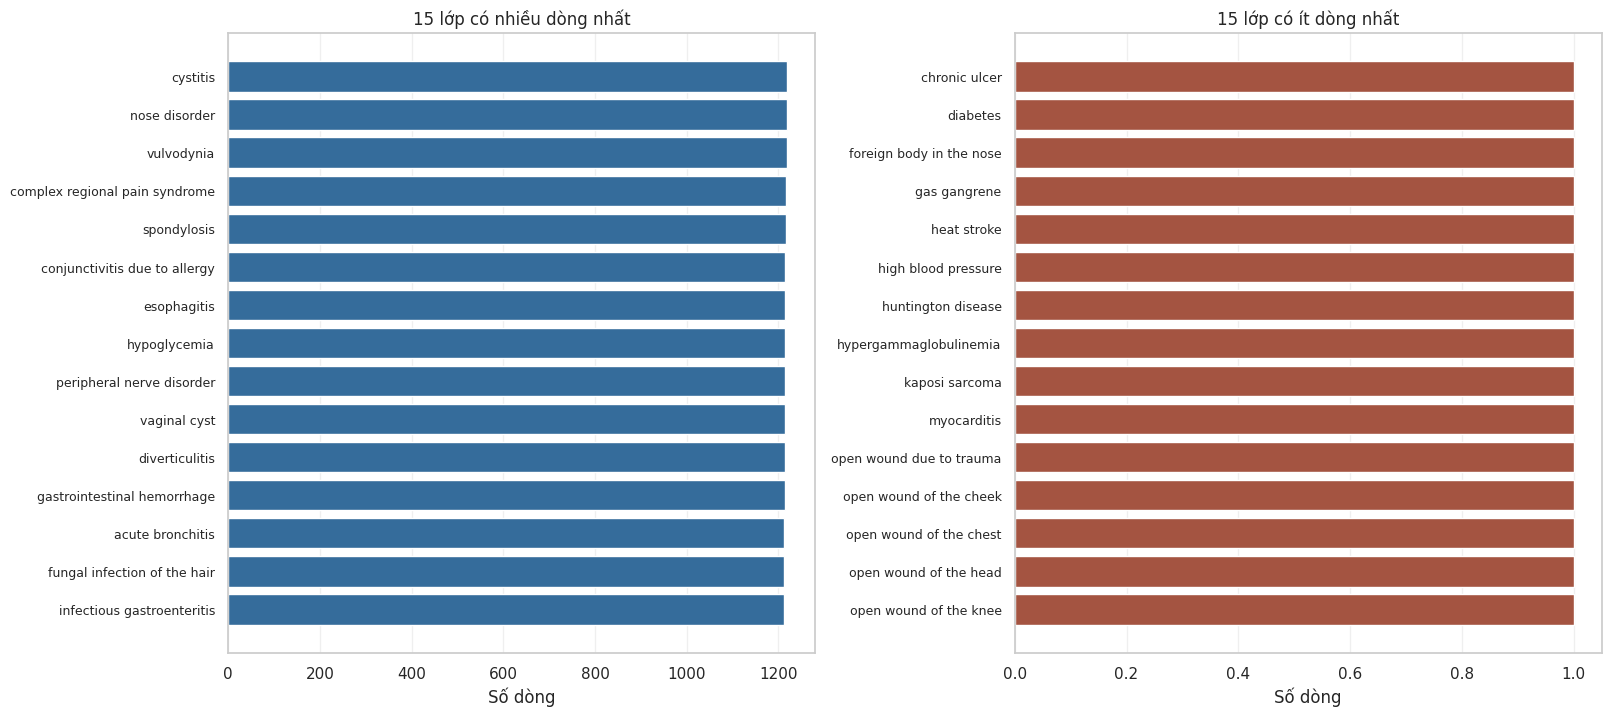

Có 52 lớp dưới 5 dòng nhưng 115 lớp dưới 5 vector. Số dòng có thể thổi phồng support; chưa lựa chọn kỹ thuật cân bằng.

In [4]:
display(eda["class_quantiles"])
show(plots.class_distribution(OUTPUT, audit))
display(Markdown(f"Mỗi lớp có {s['min_class_samples']}–{s['max_class_samples']:,} dòng, trung vị {s['median_class_samples']:g}; tỷ lệ max/min {e['imbalance_max_min_ratio']:,.0f}:1. Lớp lớn nhất chỉ chiếm {e['majority_class_fraction']:.2%}, vì vậy cần xem đồng thời đuôi lớp hiếm và macro metric."))
show(plots.extremes(OUTPUT, audit["class_distribution"], "disease", "samples", "02_class_extremes", ("15 lớp có nhiều dòng nhất", "15 lớp có ít dòng nhất")))
display(Markdown(f"Có {s['classes_with_lt5_rows']} lớp dưới 5 dòng nhưng {s['classes_with_lt5_patterns']} lớp dưới 5 vector. Số dòng có thể thổi phồng support; chưa lựa chọn kỹ thuật cân bằng."))

## B. Đặc điểm triệu chứng
Xếp tần suất trên toàn bộ dữ liệu; nhóm hiếm trên hình chỉ xét cột có xuất hiện để tách khỏi cột luôn vắng. Bảng audit vẫn chứa mọi cột.

,feature,present_count,present_fraction,diseases_with_symptom,dominant_disease,dominant_disease_rows,dominant_disease_share_when_present
0,sharp abdominal pain,32307,0.130827,135,diverticulitis,628,0.019439
1,vomiting,27874,0.112875,98,kidney stone,638,0.022889
2,headache,24719,0.100099,116,strep throat,631,0.025527
3,cough,24296,0.098386,100,acute bronchitis,626,0.025766
4,sharp chest pain,24016,0.097252,104,anxiety,636,0.026482
5,nausea,23687,0.095920,80,infectious gastroenteritis,634,0.026766
6,back pain,21809,0.088315,71,complex regional pain syndrome,649,0.029758
7,shortness of breath,21346,0.086440,101,anxiety,605,0.028343
8,fever,20394,0.082585,76,acute bronchitis,631,0.030940
9,dizziness,17272,0.069943,94,hypoglycemia,607,0.035144


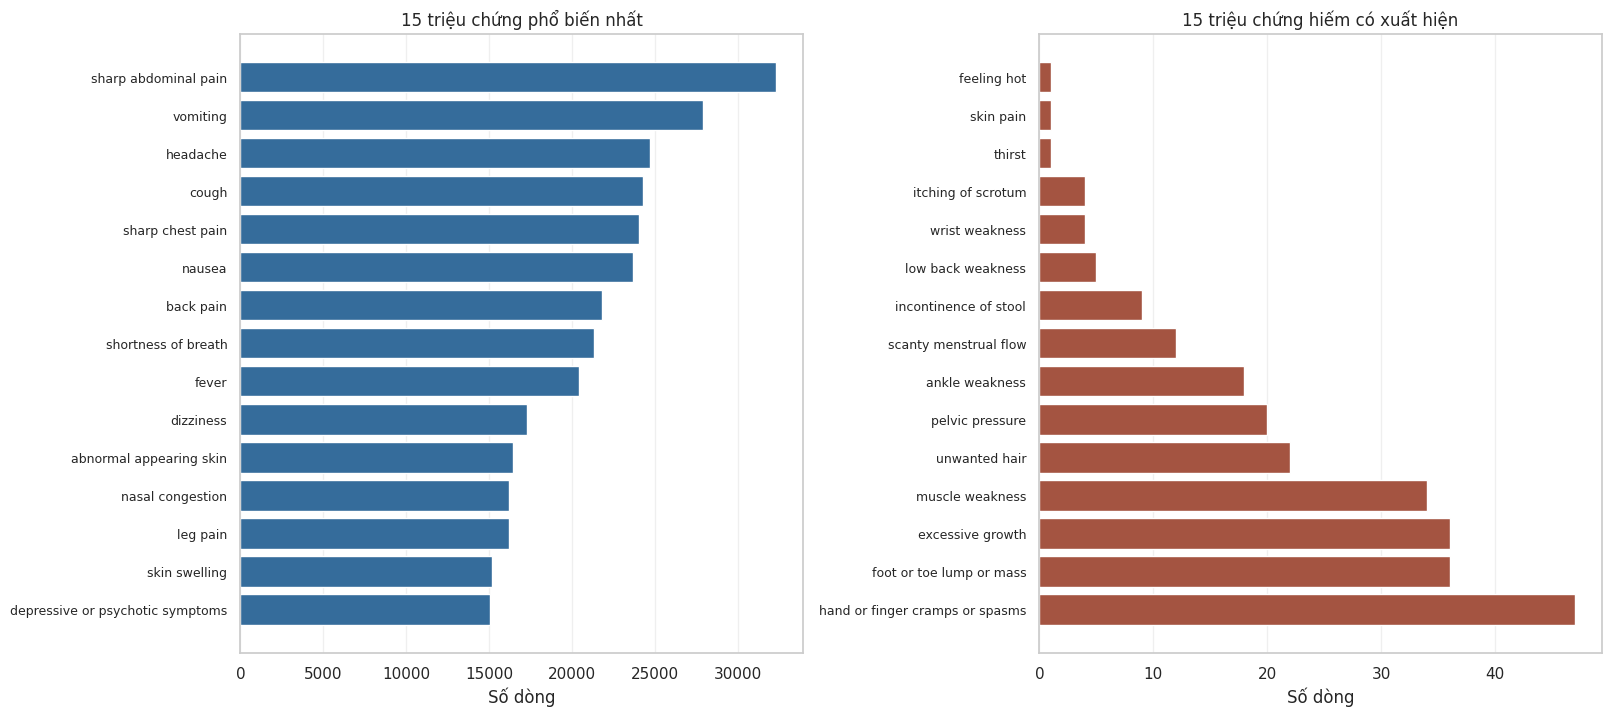

Có 49 triệu chứng luôn vắng và 0 triệu chứng luôn có; 227 cột có giá trị trội ≥99% (gồm cột hằng). Tần suất thấp có thể vẫn hữu ích cho lớp hiếm, nên đây chưa phải quyết định loại cột.

In [5]:
display(eda["symptom_frequency"].head(15))
show(plots.extremes(OUTPUT, eda["symptom_frequency"], "feature", "present_count", "03_symptom_frequency", ("15 triệu chứng phổ biến nhất", "15 triệu chứng hiếm có xuất hiện"), nonzero=True))
display(Markdown(f"Có {e['always_absent_symptoms']} triệu chứng luôn vắng và {e['always_present_symptoms']} triệu chứng luôn có; {s['near_constant_features_including_constant']} cột có giá trị trội ≥99% (gồm cột hằng). Tần suất thấp có thể vẫn hữu ích cho lớp hiếm, nên đây chưa phải quyết định loại cột."))

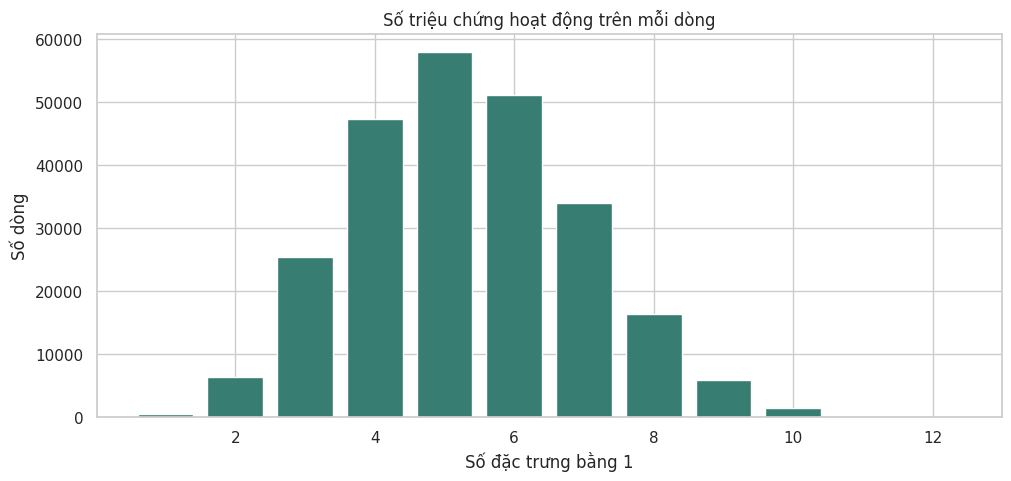

,active_symptoms,rows,fraction
0,1,443,0.001794
1,2,6448,0.026111
2,3,25451,0.103063
3,4,47283,0.191472
4,5,57989,0.234826
5,6,51116,0.206993
6,7,34037,0.137832
7,8,16425,0.066513
8,9,5980,0.024216
9,10,1534,0.006212


Trung bình 5.33, trung vị 5 triệu chứng/dòng; có 443 dòng chỉ một triệu chứng và 0 dòng toàn 0. Số triệu chứng ít có thể hạn chế phân biệt bệnh; chưa suy ra độ nặng hoặc tính hợp lý lâm sàng.

In [6]:
show(plots.active_symptoms(OUTPUT, eda))
display(eda["active_distribution"])
display(Markdown(f"Trung bình {e['active_symptoms_mean']:.2f}, trung vị {e['active_symptoms_quantiles']['0.5']:g} triệu chứng/dòng; có {e['single_symptom_rows']:,} dòng chỉ một triệu chứng và {e['all_zero_rows']:,} dòng toàn 0. Số triệu chứng ít có thể hạn chế phân biệt bệnh; chưa suy ra độ nặng hoặc tính hợp lý lâm sàng."))

### Đồng xuất hiện và tương quan
Jaccard xét phần giao/hiệp các dòng có triệu chứng; phi là Pearson cho hai biến nhị phân. Hình chỉ chọn 15 triệu chứng phổ biến nhất; các ma trận và cặp mạnh được lưu đầy đủ. Cột hằng có phi không xác định.

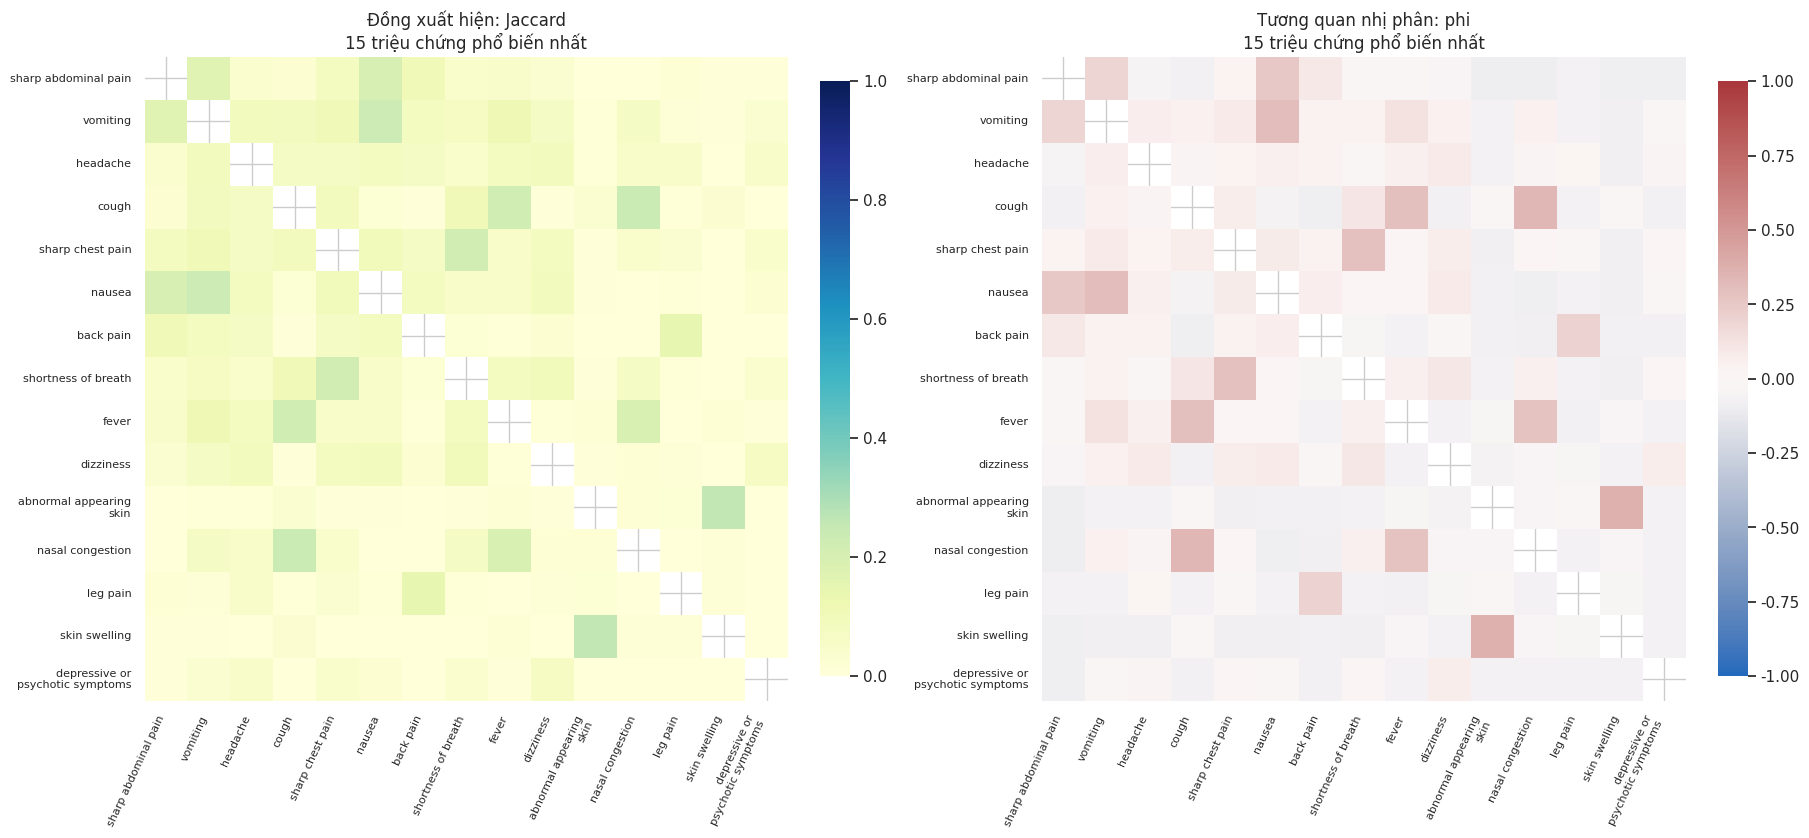

,symptom_a,symptom_b,joint_rows,phi_correlation,jaccard
17249,vomiting,nausea,9698,0.305249,0.231660
16594,sharp abdominal pain,nausea,9292,0.252551,0.198964
16592,sharp abdominal pain,vomiting,8676,0.190861,0.168450
5687,cough,fever,8115,0.301734,0.221873
752,shortness of breath,sharp chest pain,8058,0.290931,0.216009
5535,cough,nasal congestion,7712,0.335984,0.235237
16602,sharp abdominal pain,lower abdominal pain,7120,0.260244,0.177454
8093,skin swelling,abnormal appearing skin,6536,0.374153,0.260877
4811,sore throat,cough,6402,0.295337,0.200696
16646,sharp abdominal pain,burning abdominal pain,6264,0.245686,0.160517


,symptom_a,symptom_b,joint_rows,phi_correlation,jaccard


Có 0 cặp |phi| ≥0,8, trong đó 0 cặp có ≥10 dòng đồng xuất hiện. Cần xem support trước diễn giải; tương quan không chứng minh đồng nghĩa hoặc nhân quả. Không tự gộp cột.

In [7]:
show(plots.symptom_relationships(OUTPUT, eda))
display(eda["symptom_pairs"].head(10))
display(eda["strong_correlations"].head(15))
display(Markdown(f"Có {e['high_absolute_correlation_pairs']} cặp |phi| ≥0,8, trong đó {e['high_correlation_pairs_joint_ge10']} cặp có ≥10 dòng đồng xuất hiện. Cần xem support trước diễn giải; tương quan không chứng minh đồng nghĩa hoặc nhân quả. Không tự gộp cột."))

## C. Triệu chứng–bệnh và profile tương tự
Hình profile chọn bốn bệnh nhiều dòng nhất cộng cặp gần nhau có mỗi bệnh ≥20 dòng, ≥5 vector; tối đa 6 bệnh. Chọn 20 triệu chứng có tỷ lệ cao nhất trong các bệnh này. Cosine được tính từ profile trung bình của mọi bệnh, không dùng bộ phân loại.

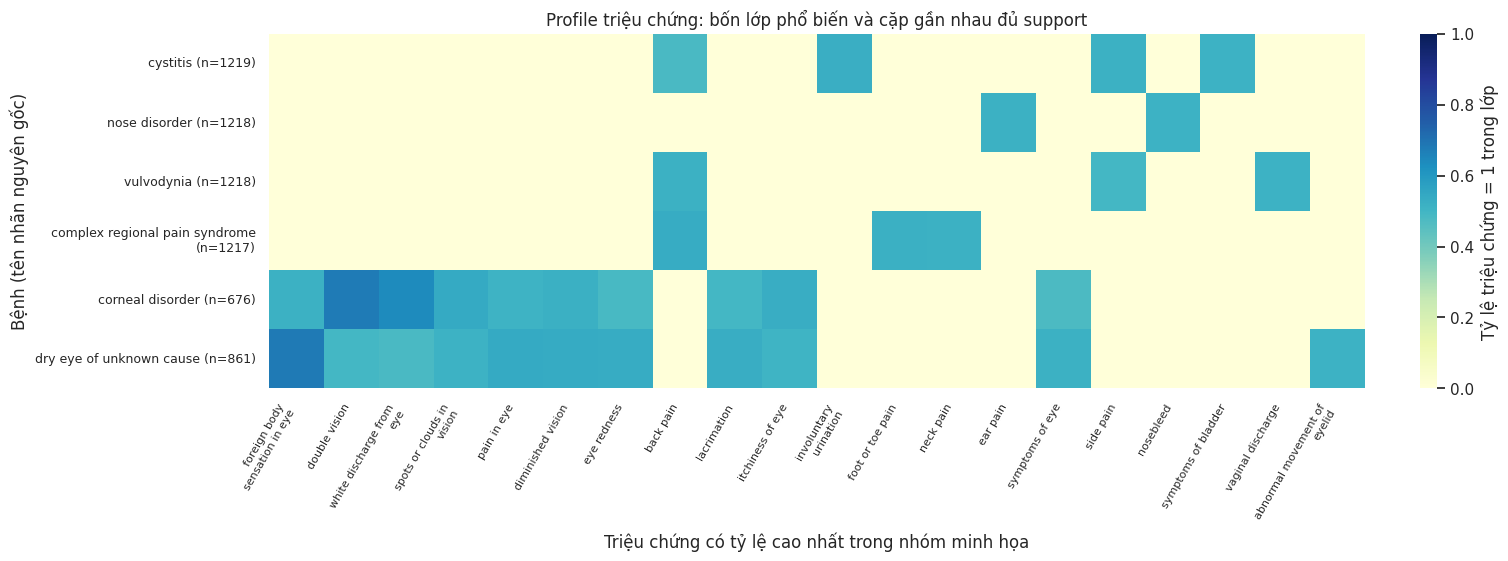

Có 40 triệu chứng chỉ xuất hiện ở một lớp (35 có ≥5 dòng). Điều đó chỉ thể hiện tính đặc hiệu trong file, không chứng minh độ nhạy hoặc tính đúng lâm sàng; có thể liên quan cơ chế sinh dữ liệu.

,feature,present_count,present_fraction,diseases_with_symptom,dominant_disease,dominant_disease_rows,dominant_disease_share_when_present,support_at_least_5
247,hip stiffness or tightness,612,0.002478,1,arthritis of the hip,612,1.0,True
261,breathing fast,468,0.001895,1,panic disorder,468,1.0,True
263,dry or flaky scalp,458,0.001855,1,seborrheic dermatitis,458,1.0,True
264,back stiffness or tightness,455,0.001843,1,chronic back pain,455,1.0,True
267,shoulder lump or mass,350,0.001417,1,lipoma,350,1.0,True
270,joint swelling,342,0.001385,1,rheumatoid arthritis,342,1.0,True
271,sore in nose,342,0.001385,1,impetigo,342,1.0,True
272,wrist lump or mass,339,0.001373,1,ganglion cyst,339,1.0,True
283,postpartum problems of the breast,252,0.001020,1,breast infection (mastitis),252,1.0,True
285,symptoms of infants,237,0.000960,1,teething syndrome,237,1.0,True


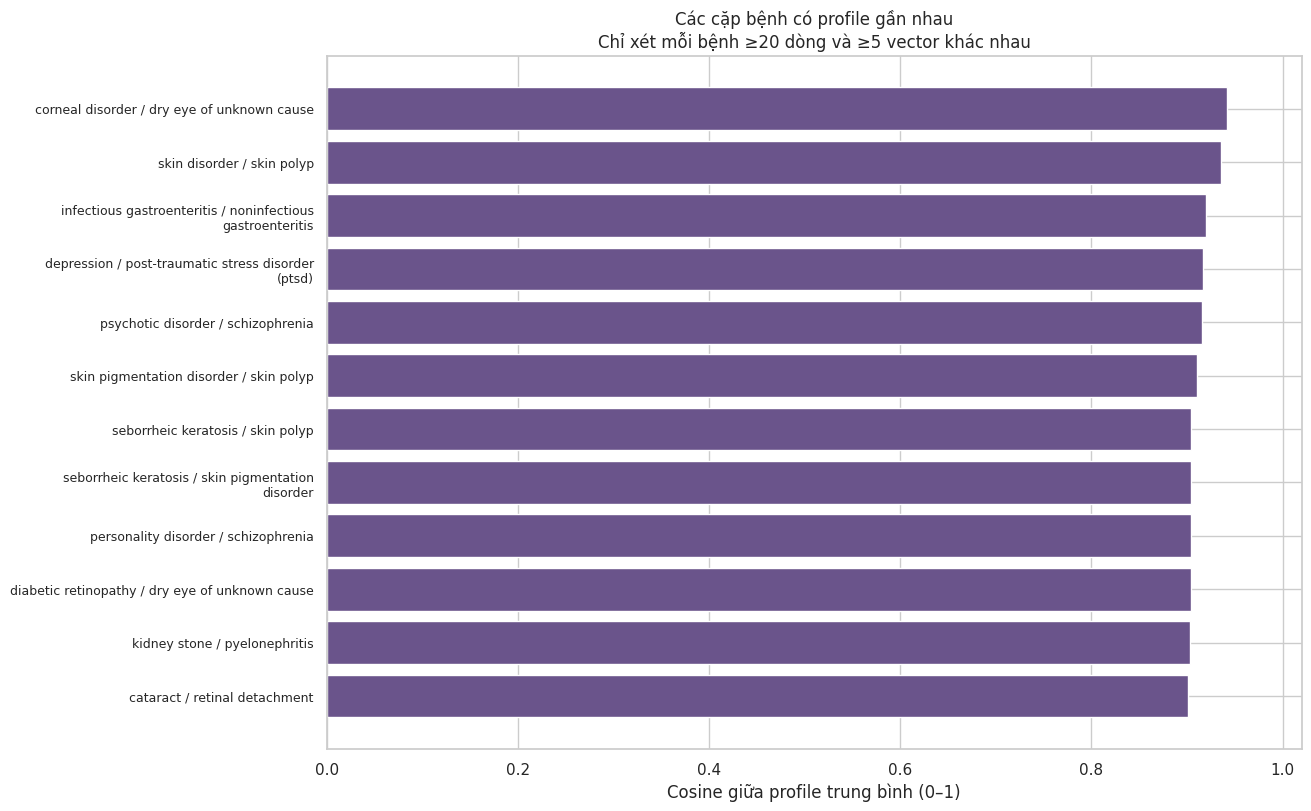

,disease_a,disease_b,cosine_similarity,rows_a,patterns_a,rows_b,patterns_b
106541,corneal disorder,dry eye of unknown cause,0.942117,676,524,861,787
291476,skin disorder,skin polyp,0.935084,676,520,897,807
217081,infectious gastroenteritis,noninfectious gastroenteritis,0.920276,1212,1212,1206,1206
119683,depression,post-traumatic stress disorder (ptsd),0.916816,912,830,607,492
284544,psychotic disorder,schizophrenia,0.915903,902,802,890,811
291592,skin pigmentation disorder,skin polyp,0.910582,909,805,897,807
290006,seborrheic keratosis,skin polyp,0.904657,870,782,897,807
290005,seborrheic keratosis,skin pigmentation disorder,0.904324,870,782,909,805
273708,personality disorder,schizophrenia,0.903959,911,816,890,811
124646,diabetic retinopathy,dry eye of unknown cause,0.903827,456,295,861,787


Cosine cao cho thấy tỷ lệ triệu chứng trung bình gần nhau, chưa chứng minh hai lớp không thể phân biệt bằng tương tác. Các cặp có support quá ít được lưu riêng và không đưa vào hình này.

In [8]:
show(plots.selected_diseases(OUTPUT, audit, eda))
display(Markdown(f"Có {e['single_class_symptoms']} triệu chứng chỉ xuất hiện ở một lớp ({e['single_class_symptoms_support_ge5']} có ≥5 dòng). Điều đó chỉ thể hiện tính đặc hiệu trong file, không chứng minh độ nhạy hoặc tính đúng lâm sàng; có thể liên quan cơ chế sinh dữ liệu."))
display(eda["single_class_features"].head(15))
show(plots.similar_diseases(OUTPUT, eda))
display(eda["supported_similar_diseases"].head(10))
display(Markdown("Cosine cao cho thấy tỷ lệ triệu chứng trung bình gần nhau, chưa chứng minh hai lớp không thể phân biệt bằng tương tác. Các cặp có support quá ít được lưu riêng và không đưa vào hình này."))

## D. Dư thừa dữ liệu và tổ hợp mơ hồ
So sánh support theo dòng với vector độc lập. Đỏ/cam trên scatter đánh dấu lớp có dòng thuộc vector nhiều nhãn. Chỉ số trùng được tính bằng equality chính xác.

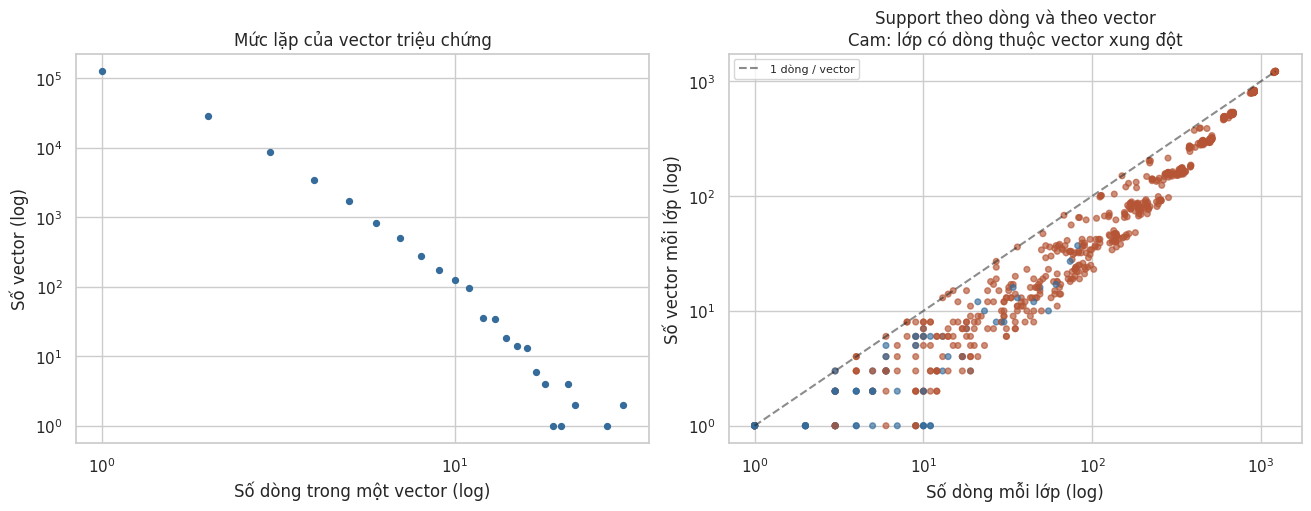

,pattern_id,active_symptoms,rows,distinct_labels,label_counts
0,4260,sharp abdominal pain,27,26,pyelonephritis: 1 | problem during pregnancy: ...
1,14853,shortness of breath | sharp chest pain,30,24,lung contusion: 1 | hyperkalemia: 1 | chronic ...
2,4087,sharp abdominal pain | nausea,30,22,pyelonephritis: 2 | problem during pregnancy: ...
3,27759,vomiting | nausea,21,21,protein deficiency: 1 | hydronephrosis: 1 | pa...
4,9789,cough | nasal congestion,22,20,asthma: 1 | teething syndrome: 1 | mastoiditis...
5,331,depressive or psychotic symptoms,19,19,panic disorder: 1 | fetal alcohol syndrome: 1 ...
6,10449,cough | fever,18,17,teething syndrome: 2 | chronic otitis media: 1...
7,1540,sore throat | cough,18,15,salivary gland disorder: 4 | acute sinusitis: ...


,disease,unique_patterns,total_rows,rows_in_conflicting_patterns
131,chronic ulcer,1,1,0
178,diabetes,1,1,0
256,foreign body in the nose,1,1,0
282,gas gangrene,1,1,0
310,heat stroke,1,1,0
325,high blood pressure,1,1,1
332,huntington disease,1,1,0
340,hypergammaglobulinemia,1,1,1
406,kaposi sarcoma,1,1,1
465,myocarditis,1,1,1


Có 169,888 vector khác nhau; 49.14% dòng thuộc nhóm lặp và 12,634 vector nhiều nhãn (16.09% dòng). Giới hạn majority theo vector trên chính file là 91.62%; đây không phải kết quả test. Có 46 lớp chỉ một vector nên không thể có train/test độc lập cho mọi lớp hiện tại.

In [9]:
show(plots.redundancy(OUTPUT, audit))
display(eda["conflict_examples"].head(8))
display(audit["class_patterns"].sort_values(["unique_patterns", "total_rows"]).head(20))
display(Markdown(f"Có {s['unique_feature_vectors']:,} vector khác nhau; {e['rows_in_repeated_patterns_fraction']:.2%} dòng thuộc nhóm lặp và {s['conflicting_pattern_groups']:,} vector nhiều nhãn ({e['conflicting_rows_fraction']:.2%} dòng). Giới hạn majority theo vector trên chính file là {s['empirical_pattern_majority_ceiling']:.2%}; đây không phải kết quả test. Có {s['classes_with_one_pattern']} lớp chỉ một vector nên không thể có train/test độc lập cho mọi lớp hiện tại."))

## E. Hàm ý nghiên cứu và xuất kết quả
Các bước sau đây chỉ xuất thống kê và khuyến nghị. Mọi phép biến đổi fit từ dữ liệu phải nằm trong train/CV ở giai đoạn sau. Toàn bộ file đã được mô tả trong EDA; chưa có test cuối được khóa.

In [10]:
export_eda(OUTPUT, eda)
report = write_eda_report(OUTPUT, audit, eda)
assert sha256_file(path) == before, "Raw thay đổi trong lúc EDA!"
display(Markdown(report.read_text(encoding="utf-8")))
print("Đã lưu báo cáo, bảng và 8 hình PNG/SVG. Dừng ở Phase 1.")

# EDA và Dataset Suitability Assessment

## Phạm vi và tính tái lập

Kết quả mô tả tính trên toàn bộ **246,945 dòng × 377 triệu chứng**, nhãn `diseases` với **773 lớp**. Không huấn luyện, lựa chọn đặc trưng, impute, scale, PCA hoặc chia train/test trong Phase 1.
Các bảng đầy đủ ở `reports/tables/`; 8 hình PNG/SVG ở `reports/figures/`. Tham số và seed nằm trong `configs/phase1.json`, fingerprint và phiên bản package nằm trong `artifacts/metadata/dataset_manifest.json`.

Nguồn ứng viên: [Disease and symptoms dataset 2023, Mendeley Data v1](https://data.mendeley.com/datasets/2cxccsxydc/1), DOI `10.17632/2cxccsxydc.1`, contributor Bran Stark, công bố 03/03/2025, CC BY 4.0 (tra cứu 21/10/2026).
Nhà xuất bản mô tả dữ liệu sinh nhân tạo. Tệp cục bộ khớp tên, schema và số lớp/đặc trưng; chưa có checksum nhà xuất bản/lịch sử tải để chứng minh danh tính bản gốc.
Không có bằng chứng độc lập về tính đại diện bệnh nhân, tỷ lệ mắc bệnh hoặc độ nặng. Không diễn giải tần suất trong CSV thành dịch tễ học.

## A. Phân bố nhãn và support

Mỗi lớp có tối thiểu **1**, tối đa **1,219**, trung vị **168** dòng; tỷ lệ max/min = **1,219:1**.
Lớp nhiều dòng nhất là `cystitis` (1,219 dòng). Tỷ trọng lớp lớn nhất = **0.49%**, 20 lớp lớn nhất = **9.83%**; không nên đánh giá mất cân bằng chỉ từ tỷ lệ max/min.
Có **52** lớp dưới 5 dòng, **115** lớp dưới 5 vector độc lập và **46** lớp chỉ một vector. Nhân bản thêm dòng không tạo thêm thông tin để đánh giá các lớp này.

| quantile | samples |
| --- | --- |
| 0.0 | 1.0 |
| 0.01 | 1.0 |
| 0.05 | 3.0 |
| 0.25 | 30.0 |
| 0.5 | 168.0 |
| 0.75 | 505.0 |
| 0.95 | 913.0 |
| 0.99 | 1215.0 |
| 1.0 | 1219.0 |

Một số lớp ít dòng (bảng đầy đủ: `audit_class_distribution.csv`):

| disease | samples |
| --- | --- |
| chronic ulcer | 1 |
| diabetes | 1 |
| foreign body in the nose | 1 |
| gas gangrene | 1 |
| heat stroke | 1 |
| high blood pressure | 1 |
| huntington disease | 1 |
| hypergammaglobulinemia | 1 |
| kaposi sarcoma | 1 |
| myocarditis | 1 |
| open wound due to trauma | 1 |
| open wound of the cheek | 1 |
| open wound of the chest | 1 |
| open wound of the head | 1 |
| open wound of the knee | 1 |

**Hình 01–02:** histogram, đường hạng với trục log và hai nhóm 15 nhãn tránh chồng hàng trăm nhãn. Chúng cho thấy cả chênh lệch kích thước lẫn đuôi lớp hiếm, chưa chứng minh kỹ thuật cân bằng nào sẽ cải thiện điểm.

## B. Triệu chứng, đồng xuất hiện và dư thừa cột

Cả 377 đặc trưng quan sát được đều là 0/1; **0** ô thiếu và **0** ô ngoài miền nhị phân.
Có **49** triệu chứng luôn vắng, **0** triệu chứng luôn có; **227** cột có giá trị trội ≥99%, gồm 49 cột hằng.
Cột hiếm có thể liên quan lớp hiếm; không tự xóa tất cả cột gần hằng. Dữ liệu không có từ điển đủ để suy ra cách xác nhận âm tính hoặc thiếu triệu chứng.

Triệu chứng phổ biến (tần suất chỉ mô tả tập sinh nhân tạo):

| feature | present_count | present_fraction |
| --- | --- | --- |
| sharp abdominal pain | 32307 | 0.13082670230213206 |
| vomiting | 27874 | 0.11287533661341595 |
| headache | 24719 | 0.10009921237522525 |
| cough | 24296 | 0.098386280345826 |
| sharp chest pain | 24016 | 0.09725242462896597 |
| nausea | 23687 | 0.09592014416165542 |
| back pain | 21809 | 0.08831521188928709 |
| shortness of breath | 21346 | 0.08644030047176497 |
| fever | 20394 | 0.08258519103444087 |
| dizziness | 17272 | 0.06994269979145154 |

Triệu chứng hiếm **có xuất hiện** (cột bằng 0 được liệt kê riêng trong audit):

| feature | present_count |
| --- | --- |
| feeling hot | 1 |
| skin pain | 1 |
| thirst | 1 |
| itching of scrotum | 4 |
| wrist weakness | 4 |
| low back weakness | 5 |
| incontinence of stool | 9 |
| scanty menstrual flow | 12 |
| ankle weakness | 18 |
| pelvic pressure | 20 |

Số triệu chứng hoạt động: trung bình **5.33**, trung vị **5**, min/max **1/12**; có **443** dòng chỉ một triệu chứng và **0** dòng toàn 0.

**Hình 03–05:** tần suất, số triệu chứng/dòng và quan hệ của 15 triệu chứng phổ biến nhất. Jaccard đo chồng lấp khi xuất hiện; phi là Pearson cho biến nhị phân. Phi không xác định cho cột hằng, được lưu NA thay vì gán 0. Không suy ra nhân quả hoặc diễn giải mức độ nặng từ đồng xuất hiện.
Có **0** cặp có |phi| ≥0,8; **0** trong số đó có ít nhất 10 dòng đồng xuất hiện. Những cặp hiếm vẫn có thể cho tương quan cao; bảng kèm `joint_rows` để xem support.
`regurgitation` và `regurgitation.1` được kiểm tra trong bảng alias; hậu tố tên không đủ làm cơ sở gộp tự động.

## C. Quan hệ triệu chứng–bệnh và khả năng phân tách

**Hình 06:** chọn bốn lớp nhiều dòng nhất cộng cặp profile gần nhất có mỗi lớp ≥20 dòng, ≥5 vector; chỉ minh họa tối đa 6 lớp và 20 triệu chứng. Bảng `eda_class_profiles.csv` chứa toàn bộ tỷ lệ P(symptom=1 | disease).
**Hình 07:** cosine của profile trung bình. Hai lớp có profile gần nhau có thể vẫn phân biệt bằng tương tác; các lớp thưa có profile ước lượng thiếu ổn định. Đây là thống kê mô tả, không phải đánh giá mô hình.

| disease_a | disease_b | cosine_similarity | rows_a | patterns_a | rows_b | patterns_b |
| --- | --- | --- | --- | --- | --- | --- |
| corneal disorder | dry eye of unknown cause | 0.9421168300646681 | 676 | 524 | 861 | 787 |
| skin disorder | skin polyp | 0.93508403685418 | 676 | 520 | 897 | 807 |
| infectious gastroenteritis | noninfectious gastroenteritis | 0.9202757963314327 | 1212 | 1212 | 1206 | 1206 |
| depression | post-traumatic stress disorder (ptsd) | 0.916816383928182 | 912 | 830 | 607 | 492 |
| psychotic disorder | schizophrenia | 0.9159034364469727 | 902 | 802 | 890 | 811 |
| skin pigmentation disorder | skin polyp | 0.9105815552783861 | 909 | 805 | 897 | 807 |
| seborrheic keratosis | skin polyp | 0.9046569438022488 | 870 | 782 | 897 | 807 |
| seborrheic keratosis | skin pigmentation disorder | 0.9043236746940798 | 870 | 782 | 909 | 805 |

Có **40** triệu chứng chỉ xuất hiện trong một lớp, **35** trong số đó có ≥5 dòng. Tính đặc hiệu trên tệp không đồng nghĩa triệu chứng đủ độ nhạy, không chứng minh tính đặc hiệu lâm sàng hoặc khả năng tổng quát hóa. Xem `eda_single_class_features.csv` và `eda_class_always_symptoms.csv`.
Mẫu rất đặc hiệu, số triệu chứng ít và việc lặp có thể tạo shortcut từ cơ chế sinh dữ liệu. Đây là dấu hiệu cần điều tra; chưa có thí nghiệm để kết luận mô hình sẽ đạt điểm cao.

## D. Mẫu lặp, xung đột và giới hạn thông tin

Có **169,888** vector khác nhau; **77,057 (31.20%)** dòng dư nếu giữ một dòng/vector. Tổng số dòng thuộc các nhóm vector lặp, tính cả dòng đầu, là **121,344 (49.14%)**.
Nếu xét cả nhãn thì có **57,298** dòng dư. Có **12,634** vector mang nhiều nhãn, liên quan **39,728 (16.09%)** dòng.

**Hình 08:** số dòng và số vector theo lớp khác nhau, cho thấy kích thước hiệu dụng không thể đo chỉ bằng số dòng.
Giới hạn ghi nhớ thực nghiệm của bộ phân loại tất định chỉ dùng triệu chứng, với trọng số mỗi dòng trên đúng tệp này, là **91.62%**: tổng số dòng của nhãn đông nhất mỗi vector chia tổng số dòng.
Đây **không** phải test accuracy, kỳ vọng hiệu năng hay giới hạn cho dữ liệu mới. Việc lọc xung đột hoặc thay đổi trọng số sẽ thay đổi con số này.
Các xung đột có thể phản ánh triệu chứng chưa đủ phân biệt nhiều bệnh hoặc nhiễu sinh dữ liệu; không thể tự quyết nhãn nào đúng.

| pattern_id | active_symptoms | rows | distinct_labels |
| --- | --- | --- | --- |
| 4260 | sharp abdominal pain | 27 | 26 |
| 14853 | shortness of breath \| sharp chest pain | 30 | 24 |
| 4087 | sharp abdominal pain \| nausea | 30 | 22 |
| 27759 | vomiting \| nausea | 21 | 21 |
| 9789 | cough \| nasal congestion | 22 | 20 |

## E. Dataset Suitability Assessment: **CONDITIONAL GO**

**Phạm vi được hỗ trợ:** nghiên cứu học phần về phân loại trên bộ triệu chứng nhị phân sinh nhân tạo, sau khi chốt cách xử lý xung đột, lớp ít group và chia nhóm. Cấu trúc có nhãn, miền giá trị hợp lệ và 169,888 vector cho phép tiếp tục thí nghiệm dưới các điều kiện này.

**Điều kiện phải giải quyết:**

1. Xác minh xuất xứ, giấy phép và cơ chế sinh nếu lấy được tài liệu gốc; phân biệt phát hiện từ file và mô tả nhà xuất bản.
2. Định nghĩa chính sách cho 12,634 vector xung đột: giữ và báo cáo giới hạn thông tin, cách ly, hoặc đổi bài toán có lý do. Không tự chọn nhãn bằng thông tin toàn bộ test.
3. Quyết định phạm vi đánh giá cho 46 lớp chỉ một vector và lớp dưới số group cần thiết; không thể yêu cầu train/test độc lập cho mọi lớp hiện tại. Muốn giữ đầy đủ 773 lớp có đánh giá độc lập cần bổ sung dữ liệu/vector phù hợp hoặc chấp nhận lớp không có test độc lập và báo cáo rõ.
4. Tất cả dòng có cùng vector phải nằm trong cùng group ở mọi phép chia, kể cả khác nhãn. Kiểm tra không giao group sau khi chia; không áp dụng phép chia phân tầng theo dòng như đánh giá chính.
5. Chưa thể dùng để khẳng định hiệu quả chẩn đoán thực tế. Không có đoàn hệ bệnh nhân xác minh, biến thời gian/cơ sở, lịch sử bệnh hay kiểm định ngoài.

## F. Ưu tiên cho Phase 2 — chỉ khuyến nghị, chưa triển khai

1. **Chốt dữ liệu và tiêu chí loại/giữ:** fingerprint, nguồn, định nghĩa nhãn, alias, quy tắc xung đột và danh sách lớp đủ support theo group. Lưu mọi thay đổi ở interim/processed, không sửa raw.
2. **Thiết kế chia nhóm trước huấn luyện:** chọn test group độc lập với mục tiêu gần 20% khi khả thi, nhưng độ bao phủ lớp/group quan trọng hơn ép tỷ lệ. StratifiedGroupKFold hoặc chiến lược group có ràng buộc chỉ được dùng sau khi kiểm tra lớp/group thực tế; không mặc định 5-fold. Tính số group mỗi lớp trên train để chọn số fold khả thi.
3. **Khóa giao thức đánh giá:** chưa tồn tại final test trong Phase 1. EDA hiện đã xem thống kê toàn bộ CSV nên không gọi một phần của nó là dữ liệu chưa từng được quan sát. Sau khi cố định quy tắc, khóa test group và ngừng dùng nó để chọn đặc trưng, trọng số voting hay tham số. Đánh giá hoàn toàn mù cần dữ liệu ngoài chưa thăm dò.
4. **Pipeline trong train/CV:** xét cột hằng, gần hằng và tương quan trong từng training fold; imputation/scaling/feature selection/PCA đều fit ở train. So sánh original với reduced bằng cùng chia group. Không loại cột hiếm theo tần suất toàn bộ CSV chỉ vì gần hằng.
5. **Baseline khi được duyệt:** majority DummyClassifier làm mốc; BernoulliNB phù hợp biểu diễn nhị phân; LogisticRegression có điều chuẩn và DecisionTree giới hạn độ sâu là các ứng viên. Chưa có kết quả để xếp hạng hoặc khẳng định lựa chọn đặc trưng/voting giúp tăng điểm.
6. **Mất cân bằng và metric:** cần ít nhất macro-F1, weighted-F1, balanced accuracy, accuracy và support/điểm theo lớp cùng độ bao phủ lớp của test. Xem thêm top-k nếu mục tiêu giao diện là gợi ý nhiều lớp. So sánh class_weight trong CV nếu mô hình hỗ trợ; mọi resampling chỉ trong train fold, không nhân bản test. Không mặc định SMOTE cho dữ liệu nhị phân/lớp cực ít group.
7. **Độ bất định và độ bền:** báo cáo kết quả theo nhóm độc lập, lặp group split/CV khi khả thi, dùng bootstrap theo group nếu tính khoảng tin cậy. Phân tích lỗi xung đột, lớp hiếm và thiếu triệu chứng; dùng kiểm định độc lập trước bất kỳ kết luận ứng dụng thật.
8. **Chuẩn bị giao diện tiếng Việt:** xây từ điển Việt–Anh có rà soát, phủ định, mức không chắc chắn và câu hỏi bổ sung. Phân biệt “không được nhắc” với “được phủ nhận”; xác minh quy ước 0 trước mã hóa. ML dự đoán, LLM chỉ hiểu ngôn ngữ/giải thích. Chưa triển khai chatbot.

**Dừng ở Phase 1.** Chỉ tiến hành preprocessing, training, ensemble hoặc chatbot sau khi người dùng duyệt.


Đã lưu báo cáo, bảng và 8 hình PNG/SVG. Dừng ở Phase 1.
